# CSAD 模型（横截面绝对偏差模型）

**用于检验羊群效应的行为金融模型**

利用个股收益 $r_i$ 和市场收益 $R_m$ 计算股票收益的横截面绝对偏差：

$$
\text{CSAD} = \frac{\sum_{i=1}^{N} |r_i - R_m|}{N}
$$

其中：

* $r_i$ 为个股 $i$ 的收益率；
* $R_m$ 为市场组合的收益率；
* $N$ 为样本中的股票数量。

以 CSAD 作为被解释变量，以市场收益的绝对值和市场收益的平方作为解释变量，进行如下时序回归：

$$
\text{CSAD}_t = \alpha + \beta_1 |R_{mt}| + \beta_2 R_{mt}^2 + \varepsilon_t
$$

## 模型说明

CSAD 模型对羊群效应的检验，主要依据时序回归中市场收益平方项（$R_{mt}^2$）前的回归系数 $\beta_2$ 的符号及显著性。当 $\beta_2$ 显著小于 0 时，表明在市场大幅上涨或大幅下跌的极端行情下，横截面绝对偏差（CSAD）显著下降，意味着个股收益趋于一致，投资者的买卖行为趋向同步，从而反映出市场中存在明显的羊群效应。当 $\beta_1$ 和 $\beta_2$ 均显著小于 0 时，说明市场羊群效应非常显著，投资者在极端行情下的从众行为尤为突出。

数据：日度收盘价、日度可交易股票数量

In [6]:
import numpy as np
import pandas as pd
from rqdatac import all_instruments, get_price, get_trading_dates

def _get_ids(stock_ids=None):
    """默认返回米筐 CS 股票全集。"""
    if stock_ids is not None:
        return list(dict.fromkeys(stock_ids))

    return (
        all_instruments("CS")
        .order_book_id
        .dropna()
        .drop_duplicates()
        .tolist()
    )

def _prepare_dates(start_date, end_date, lookback_days):
    """
    返回：
    target_dates：最终需要输出因子的交易日；
    price_dates：为计算滚动收益而额外向前展开后的价格日期。
    """
    start_date = pd.Timestamp(start_date)
    end_date = pd.Timestamp(end_date)

    calendar = pd.DatetimeIndex(
        get_trading_dates(
            start_date=start_date - pd.Timedelta(days=max(lookback_days * 3, 90)),
            end_date=end_date,
        )
    )

    target_dates = calendar[
        (calendar >= start_date) & (calendar <= end_date)
    ]

    if len(target_dates) == 0:
        raise ValueError("所选区间内没有交易日。")

    first_loc = calendar.get_loc(target_dates[0])
    last_loc = calendar.get_loc(target_dates[-1])

    if first_loc < lookback_days:
        raise ValueError("历史交易日不足，无法满足滚动窗口。")

    price_dates = calendar[first_loc - lookback_days:last_loc + 1]
    return target_dates, price_dates


def _get_batch_close_volume(batch, price_dates):
    """
    米筐多标的查询不能使用 skip_suspended=True；
    因此下载成交量，并用 volume > 0 排除当日停牌股票。
    """
    raw = get_price(
        order_book_ids=batch,
        start_date=price_dates[0],
        end_date=price_dates[-1],
        frequency="1d",
        fields=["close", "volume"],
        adjust_type="pre",
        skip_suspended=False,
        expect_df=True,
    )

    if raw is None or raw.empty:
        return None, None

    if isinstance(raw.index, pd.MultiIndex):
        close = raw["close"].unstack("order_book_id")
        volume = raw["volume"].unstack("order_book_id")
    else:
        close = raw[["close"]].rename(columns={"close": batch[0]})
        volume = raw[["volume"]].rename(columns={"volume": batch[0]})

    close.index = pd.to_datetime(close.index)
    volume.index = pd.to_datetime(volume.index)

    return (
        close.reindex(index=price_dates, columns=batch),
        volume.reindex(index=price_dates, columns=batch),
    )

# 旧函数
# def _get_returns(close, volume):
#     """仅保留当日实际有成交的股票收益率。"""
#     returns = close.pct_change(fill_method=None).iloc[1:]
#     traded_today = volume.iloc[1:].gt(0)
#     return returns.where(traded_today)

# 新函数，只保留前后两个交易日均正常成交的日收益，避免复牌日后的异常涨幅
def _get_returns(close, volume):
    """只保留前后两个交易日均正常成交的日收益。"""
    returns = close.pct_change(fill_method=None).iloc[1:]

    traded_today = volume.iloc[1:].gt(0)
    traded_yesterday = volume.shift(1).iloc[1:].gt(0)

    valid_price = (
        close.iloc[1:].gt(0)
        & close.shift(1).iloc[1:].gt(0)
    )

    return returns.where(traded_today & traded_yesterday & valid_price)

def calculate_csad_beta_factor(
    start_date,
    end_date,
    factor_type=0,
    regression_window=252,
    market_ids=None,
    batch_size=500,
    min_market_stocks=500,
):
    """
    日频滚动 CSAD 羊群效应因子。

    CSAD_t = mean_i(|r_i,t - R_m,t|)

    回归：
    CSAD_t = alpha + beta1 * |R_m,t| + beta2 * R_m,t^2 + epsilon_t

    参数
    ----
    factor_type : int
        0：输出 beta1；
        1：输出 beta2。

    返回
    ----
    DataFrame
        日期单层索引；
        列名为 CSAD_beta1 或 CSAD_beta2。
    """
    if factor_type not in (0, 1):
        raise ValueError("factor_type 只能为 0（beta1）或 1（beta2）。")

    if regression_window < 20:
        raise ValueError("regression_window 建议不小于 20。")

    target_dates, price_dates = _prepare_dates(
        start_date=start_date,
        end_date=end_date,
        # 需要一段历史 CSAD 序列，才能在第一个输出日进行滚动回归。
        lookback_days=regression_window,
    )

    market_ids = _get_ids(market_ids)
    return_dates = price_dates[1:]

    # 第一步：计算每日市场等权收益率 R_m,t。
    return_sum = pd.Series(0.0, index=return_dates)
    stock_count = pd.Series(0, index=return_dates, dtype="int64")

    for start in range(0, len(market_ids), batch_size):
        batch = market_ids[start:start + batch_size]

        close, volume = _get_batch_close_volume(batch, price_dates)
        if close is None:
            continue

        returns = _get_returns(close, volume)

        return_sum += returns.sum(axis=1, skipna=True)
        stock_count += returns.notna().sum(axis=1).astype("int64")

    market_return = (
        return_sum / stock_count.replace(0, np.nan)
    ).where(stock_count >= min_market_stocks)

    # 第二步：计算 CSAD_t。
    absolute_deviation_sum = pd.Series(0.0, index=return_dates)
    absolute_deviation_count = pd.Series(
        0, index=return_dates, dtype="int64"
    )

    for start in range(0, len(market_ids), batch_size):
        batch = market_ids[start:start + batch_size]

        close, volume = _get_batch_close_volume(batch, price_dates)
        if close is None:
            continue

        returns = _get_returns(close, volume)

        absolute_deviation = returns.sub(
            market_return,
            axis=0,
        ).abs()

        absolute_deviation_sum += absolute_deviation.sum(
            axis=1,
            skipna=True,
        )

        absolute_deviation_count += absolute_deviation.notna().sum(
            axis=1
        ).astype("int64")

    csad = (
        absolute_deviation_sum
        / absolute_deviation_count.replace(0, np.nan)
    )

    state = pd.DataFrame({
        "market_return": market_return,
        "CSAD": csad,
        "N": absolute_deviation_count,
    })

    state.loc[
        state["N"] < min_market_stocks,
        ["market_return", "CSAD"],
    ] = np.nan

    state = state.dropna(subset=["market_return", "CSAD"]).copy()

    # 回归解释变量。
    state["abs_market_return"] = state["market_return"].abs()
    state["market_return_sq"] = state["market_return"].pow(2)

    beta_result = pd.DataFrame(
        np.nan,
        index=state.index,
        columns=["CSAD_beta1", "CSAD_beta2"],
    )

    # 每日仅使用截至当日的历史窗口，避免未来函数。
    for end_pos in range(regression_window - 1, len(state)):
        sample = state.iloc[
            end_pos - regression_window + 1:end_pos + 1
        ]

        y = sample["CSAD"].values

        X = np.column_stack([
            np.ones(len(sample)),
            sample["abs_market_return"].values,
            sample["market_return_sq"].values,
        ])

        if np.linalg.matrix_rank(X) < X.shape[1]:
            continue

        # alpha、beta1、beta2
        coefficients = np.linalg.lstsq(X, y, rcond=None)[0]

        beta_result.iloc[end_pos, 0] = coefficients[1]
        beta_result.iloc[end_pos, 1] = coefficients[2]

    beta_result = beta_result.reindex(target_dates)

    if factor_type == 0:
        return beta_result[["CSAD_beta1"]]

    return beta_result[["CSAD_beta2"]]

In [2]:
csad_beta1 = calculate_csad_beta_factor(
    start_date="2020-01-01",
    end_date="2025-12-31",
    factor_type=0,
    regression_window=252,
)

csad_beta1.head()

,CSAD_beta1
2020-01-02,0.110383
2020-01-03,0.109439
2020-01-06,0.109154
2020-01-07,0.108944
2020-01-08,0.109661


In [3]:
csad_beta2 = calculate_csad_beta_factor(
    start_date="2020-01-01",
    end_date="2025-12-31",
    factor_type=1,
    regression_window=252,
)

csad_beta2.head()

,CSAD_beta2
2020-01-02,0.330908
2020-01-03,0.339363
2020-01-06,0.333873
2020-01-07,0.333741
2020-01-08,0.320148


重复日期：0
beta1、beta2 有效日期不一致的天数：0


,因子,总交易日数,有效观测数,缺失值数,最长连续缺失,无穷值,首个有效日期,负值占比,均值,标准差,最小值,P01,中位数,P99,最大值,日变化绝对值P99
0,CSAD_beta1,1455,1455,0,0,0,2020-01-02,0.076289,0.098582,0.059171,-0.105206,-0.085305,0.112351,0.173397,0.179855,0.023795
1,CSAD_beta2,1455,1455,0,0,0,2020-01-02,0.372509,1.337115,2.277736,-1.696377,-1.351578,0.821863,8.812981,9.450142,1.057881


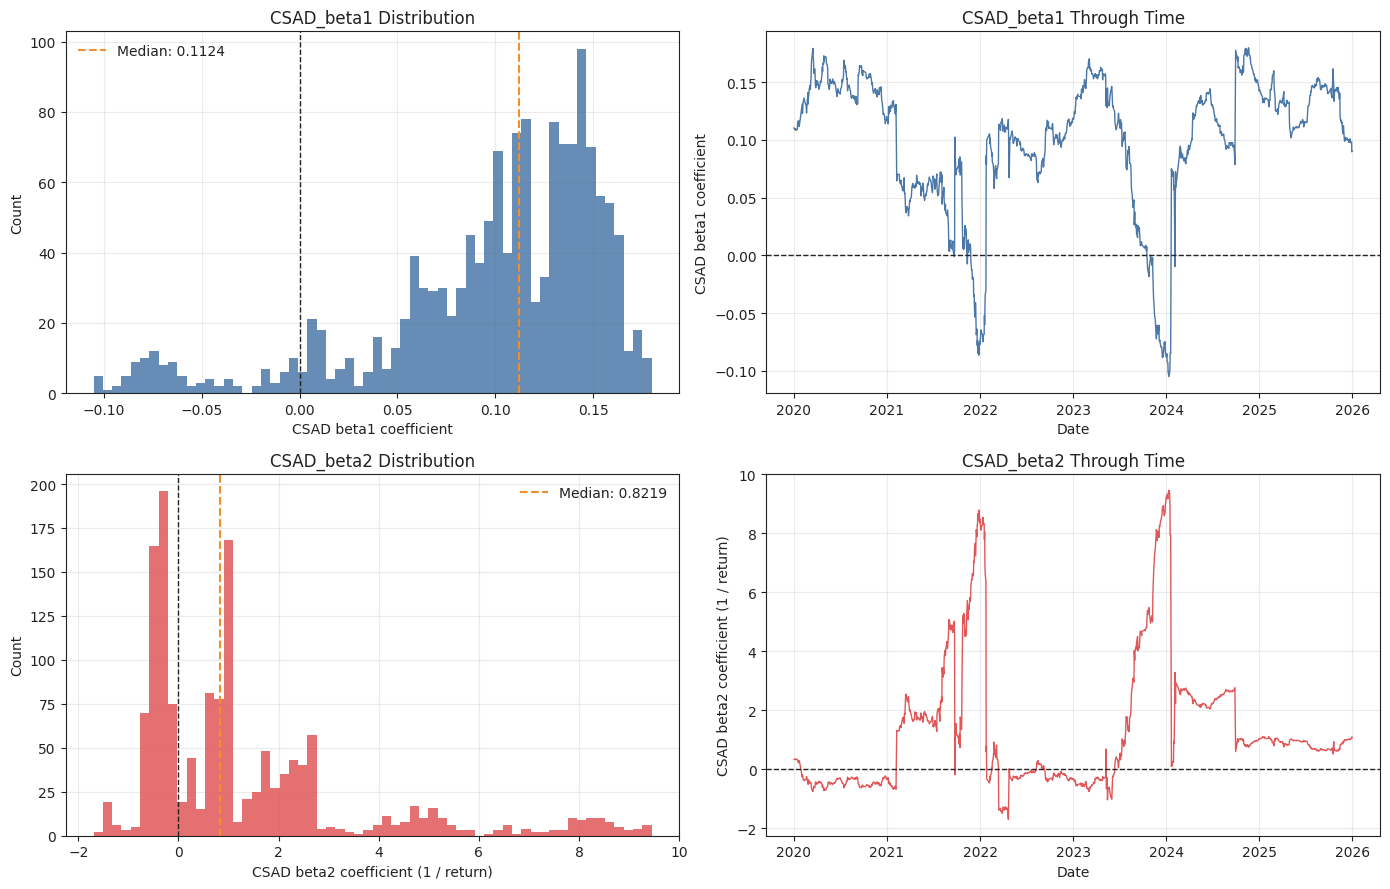

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 合并两个回归系数
data = csad_beta1[["CSAD_beta1"]].join(
    csad_beta2[["CSAD_beta2"]],
    how="outer",
).sort_index()

data.index = pd.to_datetime(data.index)
data["CSAD_beta1"] = pd.to_numeric(data["CSAD_beta1"], errors="coerce")
data["CSAD_beta2"] = pd.to_numeric(data["CSAD_beta2"], errors="coerce")

def longest_missing_run(series):
    invalid = series.replace([np.inf, -np.inf], np.nan).isna()
    return int(invalid.groupby((~invalid).cumsum()).sum().max())

duplicate_count = int(data.index.duplicated().sum())
date_mismatch = int(
    (data["CSAD_beta1"].notna() != data["CSAD_beta2"].notna()).sum()
)

summary_rows = []

for column in ["CSAD_beta1", "CSAD_beta2"]:
    series = data[column]
    valid = series.replace([np.inf, -np.inf], np.nan).dropna()

    if valid.empty:
        raise ValueError("{} 没有有效观测。".format(column))

    summary_rows.append({
        "因子": column,
        "总交易日数": len(series),
        "有效观测数": len(valid),
        "缺失值数": int(series.isna().sum()),
        "最长连续缺失": longest_missing_run(series),
        "无穷值": int(np.isinf(series.dropna().values).sum()),
        "首个有效日期": valid.index.min().strftime("%Y-%m-%d"),
        "负值占比": (valid < 0).mean(),
        "均值": valid.mean(),
        "标准差": valid.std(),
        "最小值": valid.min(),
        "P01": valid.quantile(0.01),
        "中位数": valid.median(),
        "P99": valid.quantile(0.99),
        "最大值": valid.max(),
        "日变化绝对值P99": valid.diff().abs().quantile(0.99),
    })

summary = pd.DataFrame(summary_rows)

print("重复日期：{}".format(duplicate_count))
print("beta1、beta2 有效日期不一致的天数：{}".format(date_mismatch))
display(summary)

# ---------- 绘图 ----------
plt.style.use("default")
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "axes.edgecolor": "#222222",
    "axes.labelcolor": "#222222",
    "xtick.color": "#222222",
    "ytick.color": "#222222",
    "text.color": "#222222",
})

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

plot_config = [
    ("CSAD_beta1", "#4C78A8", "CSAD beta1 coefficient"),
    ("CSAD_beta2", "#E15759", "CSAD beta2 coefficient (1 / return)"),
]

for row, (column, color, ylabel) in enumerate(plot_config):
    valid = data[column].replace([np.inf, -np.inf], np.nan).dropna()

    # 左：分布
    axes[row, 0].hist(valid.values, bins=60, color=color, alpha=0.85)
    axes[row, 0].axvline(0, color="#222222", linestyle="--", linewidth=1)
    axes[row, 0].axvline(
        valid.median(),
        color="#F28E2B",
        linestyle="--",
        label="Median: {:.4f}".format(valid.median()),
    )
    axes[row, 0].set_title("{} Distribution".format(column))
    axes[row, 0].set_xlabel(ylabel)
    axes[row, 0].set_ylabel("Count")
    axes[row, 0].legend(frameon=False)
    axes[row, 0].grid(alpha=0.25)
    axes[row, 0].set_axisbelow(True)

    # 右：时间序列
    axes[row, 1].plot(valid.index, valid.values, color=color, linewidth=1)
    axes[row, 1].axhline(0, color="#222222", linestyle="--", linewidth=1)
    axes[row, 1].set_title("{} Through Time".format(column))
    axes[row, 1].set_xlabel("Date")
    axes[row, 1].set_ylabel(ylabel)
    axes[row, 1].grid(alpha=0.25)
    axes[row, 1].set_axisbelow(True)

plt.tight_layout()
plt.show()

# 保存图片：
# plt.savefig("CSAD_beta_distribution.png", dpi=200, bbox_inches="tight")

> 这里最关键的是 beta2：只有它显著小于零，才符合 CSAD 模型所说的“市场波动越极端，个股收益越趋同”的羊群效应。

CSAD 的 beta 输出质量通过：1455 个交易日全部有效、无缺失、无重复、无无穷值，时间序列连续。

数值也基本合理，但金融结论是“存在阶段性候选羊群，未形成稳定羊群”。

| 系数 | 结果 | 金融含义 |
|---|---:|---|
| beta1 | 均值 `+0.0986`，仅 7.63% 为负 | 市场收益绝对值增加时，CSAD 通常上升，股票分歧扩大 |
| beta2 | 中位数 `+0.8219`，均值 `+1.3371`，37.25% 为负 | 二次项方向不稳定；多数窗口不支持羊群，部分窗口可能存在非线性收敛 |

特别注意：`beta2` 的数值不能按百分比直接读。它乘的是 `Rm²`。

例如市场收益为 2%：

- beta1 平均贡献：`0.0986 × 0.02 ≈ 0.00197`，即 CSAD 增加约 **0.20 个百分点**；
- beta2 取中位数时的贡献：`0.8219 × 0.02² ≈ 0.00033`，即增加约 **0.03 个百分点**；
- beta2 即使为 `9`，在 2% 市场波动下的贡献也只是 `9 × 0.0004 = 0.0036`，即 **0.36 个百分点**。所以 beta2 的 `9.45` 并非数值错误。

金融逻辑上：

- `beta1` 大部分为正，符合市场波动增大时股票因行业、规模、估值和风险暴露不同而产生更大收益分歧的常规情形。
- `beta2` 有 37.25% 为负，说明约三分之一滚动窗口中，CSAD 曲线可能向下弯曲，是羊群效应的候选时期。
- 但 beta2 的中位数、均值、99% 分位数均为正，且标准差较大，说明这种负二次关系不稳定，不能得出“全样本存在稳定 CSAD 羊群效应”的结论。
- 真正有意义的结论需要检查：`beta2 < 0` 是否显著，以及在 beta2 为负时，`beta1 + 2 × beta2 × |Rm|` 是否真的转为负。否则可能只是“分歧增长变慢”，还没有发展到“分歧随市场波动增大而下降”。

因此当前应写为：**CSAD 因子数据质量通过；全样本不支持稳定羊群效应，但存在值得结合 t 值和时间段进一步检验的阶段性负 beta2。**